In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
#!/bin/bash
!kaggle datasets download blastchar/telco-customer-churn

Dataset URL: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
License(s): copyright-authors
telco-customer-churn.zip: Skipping, found more recently modified local copy (use --force to force download)


In [3]:
!unzip telco-customer-churn.zip

Archive:  telco-customer-churn.zip
replace WA_Fn-UseC_-Telco-Customer-Churn.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: WA_Fn-UseC_-Telco-Customer-Churn.csv  


In [4]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
data = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [7]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
num_cols = df.select_dtypes(exclude='object').columns.tolist()

In [8]:
df[cat_cols]

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
0,7590-VHVEG,Female,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,No
1,5575-GNVDE,Male,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,1889.5,No
2,3668-QPYBK,Male,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,108.15,Yes
3,7795-CFOCW,Male,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),1840.75,No
4,9237-HQITU,Female,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,Yes,Yes,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,1990.5,No
7039,2234-XADUH,Female,Yes,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),7362.9,No
7040,4801-JZAZL,Female,Yes,Yes,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,346.45,No
7041,8361-LTMKD,Male,Yes,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,306.6,Yes


In [9]:
df[cat_cols].nunique()

,0
customerID,7043
gender,2
Partner,2
Dependents,2
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3
OnlineBackup,3
DeviceProtection,3


In [10]:
df[num_cols]

,SeniorCitizen,tenure,MonthlyCharges
0,0,1,29.85
1,0,34,56.95
2,0,2,53.85
3,0,45,42.30
4,0,2,70.70
...,...,...,...
7038,0,24,84.80
7039,0,72,103.20
7040,0,11,29.60
7041,1,4,74.40


In [11]:
df = df.drop(columns= ["customerID"] )
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [12]:
df["TotalCharges"] = (df["TotalCharges"].str.strip()).replace("" , 0).astype("float")

In [13]:
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [14]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
num_cols = df.select_dtypes(exclude='object').columns.tolist()

In [15]:
df[cat_cols]

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,Female,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,No
1,Male,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,No
2,Male,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,Yes
3,Male,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),No
4,Female,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,Yes,Yes,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,No
7039,Female,Yes,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),No
7040,Female,Yes,Yes,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
7041,Male,Yes,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,Yes


In [16]:
df[cat_cols].nunique()

,0
gender,2
Partner,2
Dependents,2
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3
OnlineBackup,3
DeviceProtection,3
TechSupport,3


In [17]:
df[num_cols]

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,0,1,29.85,29.85
1,0,34,56.95,1889.50
2,0,2,53.85,108.15
3,0,45,42.30,1840.75
4,0,2,70.70,151.65
...,...,...,...,...
7038,0,24,84.80,1990.50
7039,0,72,103.20,7362.90
7040,0,11,29.60,346.45
7041,1,4,74.40,306.60


In [18]:
df['SeniorCitizen'].unique()

array([0, 1])

In [19]:
df['tenure'].nunique()

73

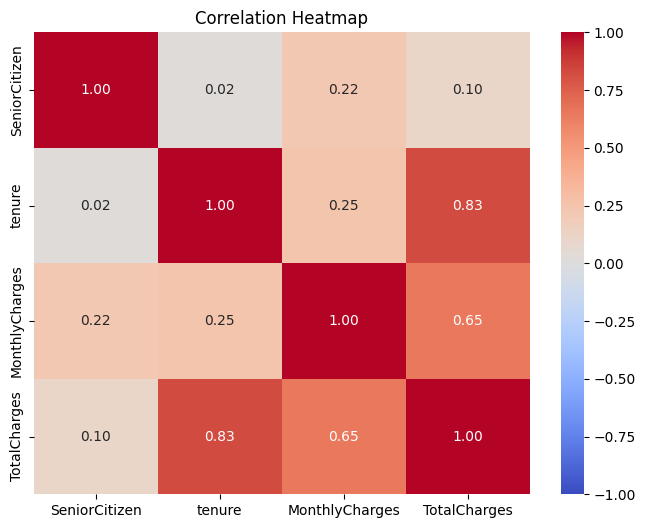

In [20]:
# heat map for corr (num cols)
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import pandas as pd

# Separate features (X) and target (y)
X = df.drop(columns=['Churn'])
y = df['Churn']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Identify numerical and categorical columns
numerical_cols = X_train.select_dtypes(include='number').columns.tolist()
categorical_cols = X_train.select_dtypes(exclude='number').columns.tolist()

# Encode categorical features
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = pd.DataFrame(
    encoder.fit_transform(X_train[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    encoder.transform(X_test[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_test.index
)

# Remove original categorical columns and add encoded columns
X_train = pd.concat(
    [X_train.drop(columns=categorical_cols), X_train_encoded],
    axis=1
)

X_test = pd.concat(
    [X_test.drop(columns=categorical_cols), X_test_encoded],
    axis=1
)

# Scale numerical features
scaler = StandardScaler()

X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

# Display the final shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 45)
X_test: (1409, 45)
y_train: (5634,)
y_test: (1409,)


In [22]:
X_train[numerical_cols]

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
3738,-0.441773,0.102371,-0.521976,-0.262257
3151,-0.441773,-0.711743,0.337478,-0.503635
4860,-0.441773,-0.793155,-0.809013,-0.749883
3867,-0.441773,-0.263980,0.284384,-0.172722
3810,-0.441773,-1.281624,-0.676279,-0.989374
...,...,...,...,...
6303,-0.441773,1.567778,1.470695,2.373129
6227,-0.441773,-1.240918,-0.626504,-0.973665
4673,2.263606,-0.304686,1.256662,0.158344
2710,-0.441773,-0.345392,-1.477661,-0.797075


In [23]:
from sklearn.preprocessing import LabelEncoder

encode2 = LabelEncoder()
y_train = encode2.fit_transform(y_train)
y_test = encode2.transform(y_test)

In [24]:
X_train

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,-0.441773,0.102371,-0.521976,-0.262257,0.0,1.0,1.0,0.0,1.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3151,-0.441773,-0.711743,0.337478,-0.503635,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4860,-0.441773,-0.793155,-0.809013,-0.749883,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3867,-0.441773,-0.263980,0.284384,-0.172722,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3810,-0.441773,-1.281624,-0.676279,-0.989374,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6303,-0.441773,1.567778,1.470695,2.373129,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
6227,-0.441773,-1.240918,-0.626504,-0.973665,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4673,2.263606,-0.304686,1.256662,0.158344,1.0,0.0,1.0,0.0,1.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2710,-0.441773,-0.345392,-1.477661,-0.797075,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [25]:
y_train

array([0, 0, 0, ..., 1, 0, 0])

what we do now

We will use `RandomizedSearchCV` to find the best hyperparameters for five models: Logistic Regression, KNN, Linear SVM, RBF SVM, and Polynomial SVM. We will test different parameter combinations using 3-fold cross-validation and selected the best parameters based on Accuracy. Finally, evaluate each best model on the test set and compared Accuracy, F1 Score, and Recall to determine the best-performing model.

In [27]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.base import clone
import pandas as pd

# Models and Hyperparameter search spaces
models_params = {
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=3000, random_state=42),
        "params": {
            "C": [0.01, 0.1, 1, 10, 100],
            "solver": ["lbfgs"],
            "class_weight": [None, "balanced"]
        }
    },

    "KNN": {
        "model": KNeighborsClassifier(),
        "params": {
            "n_neighbors": [5, 7, 9, 11, 15, 21],
            "weights": ["uniform", "distance"],
            "p": [1, 2]
        }
    },

    "Linear SVM": {
        "model": LinearSVC(max_iter=10000, random_state=42),
        "params": {
            "C": [0.01, 0.1, 1, 10, 100],
            "class_weight": [None, "balanced"]
        }
    },

    "RBF SVM": {
        "model": SVC(kernel="rbf"),
        "params": {
            "C": [0.1, 1, 10, 100],
            "gamma": ["scale", 0.01, 0.1, 1],
            "class_weight": [None, "balanced"]
        }
    },

    "Polynomial SVM (degree=2)": {
        "model": SVC(kernel="poly", degree=2),
        "params": {
            "C": [0.1, 1, 10, 100],
            "gamma": ["scale", 0.01, 0.1, 1],
            "coef0": [0, 1],
            "class_weight": [None, "balanced"]
        }
    }
}

results = {}

for name, config in models_params.items():
    print(f"\n{'=' * 50}")
    print(f"Searching: {name}")

    search = RandomizedSearchCV(
        estimator=config["model"],
        param_distributions=config["params"],
        n_iter=10,
        scoring="accuracy",
        cv=3,
        n_jobs=-1,
        random_state=42,
        verbose=1
    )

    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    y_pred = best_model.predict(X_test)

    results[name] = {
        "Best Parameters": search.best_params_,
        "Best CV Accuracy": search.best_score_,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test F1": f1_score(y_test, y_pred, pos_label=1),
        "Test Recall": recall_score(y_test, y_pred, pos_label=1),
        "Best Model": best_model
    }

    print("Best Parameters:", search.best_params_)
    print("Best CV Accuracy:", round(search.best_score_, 4))
    print("Test Accuracy:", round(results[name]["Test Accuracy"], 4))
    print("Test F1:", round(results[name]["Test F1"], 4))
    print("Test Recall:", round(results[name]["Test Recall"], 4))


Searching: Logistic Regression
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters: {'solver': 'lbfgs', 'class_weight': None, 'C': 0.01}
Best CV Accuracy: 0.8055
Test Accuracy: 0.7991
Test F1: 0.5693
Test Recall: 0.5

Searching: KNN
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters: {'weights': 'uniform', 'p': 1, 'n_neighbors': 15}
Best CV Accuracy: 0.787
Test Accuracy: 0.7722
Test F1: 0.5633
Test Recall: 0.5535

Searching: Linear SVM
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters: {'class_weight': None, 'C': 1}
Best CV Accuracy: 0.8056
Test Accuracy: 0.8013
Test F1: 0.5918
Test Recall: 0.5428

Searching: RBF SVM
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters: {'gamma': 0.01, 'class_weight': None, 'C': 10}
Best CV Accuracy: 0.8076
Test Accuracy: 0.7942
Test F1: 0.5538
Test Recall: 0.4813

Searching: Polynomial SVM (degree=2)
Fitting 3 folds for each of 10 candidates, totalli

In [28]:
model1 = LogisticRegression(
    C=0.01,
    solver='lbfgs',
    max_iter=3000,
    class_weight=None,
    random_state=42
)

model2 = KNeighborsClassifier(
    n_neighbors=15,
    weights='uniform',
    algorithm='auto',
    leaf_size=30,
    p=1,
    metric='minkowski',
    metric_params=None,
    n_jobs=-1
)

model3 = LinearSVC(
    C=1,
    penalty='l2',
    loss='squared_hinge',
    dual=True,
    tol=0.0001,
    class_weight=None,
    max_iter=10000,
    random_state=42
)

model4 = SVC(
    C=10,
    kernel='rbf',
    gamma=0.01,
    class_weight=None,
    probability=True,
    random_state=42
)

model5 = SVC(
    C=1,
    kernel='poly',
    degree=2,
    gamma='scale',
    coef0=0,
    class_weight=None,
    probability=True,
    random_state=42
)

In [29]:
model1.fit(X_train , y_train)
y_train_pred1 = model1.predict(X_train)
y_test_pred1 = model1.predict(X_test)

In [30]:
model2.fit(X_train , y_train)
y_train_pred2 = model2.predict(X_train)
y_test_pred2 = model2.predict(X_test)

In [31]:
model3.fit(X_train , y_train)
y_train_pred3 = model3.predict(X_train)
y_test_pred3 = model3.predict(X_test)

In [32]:
model4.fit(X_train , y_train)
y_train_pred4 = model4.predict(X_train)
y_test_pred4 = model4.predict(X_test)

In [33]:
model5.fit(X_train , y_train)
y_train_pred5 = model5.predict(X_train)
y_test_pred5 = model5.predict(X_test)

In [34]:
from sklearn.metrics import accuracy_score,confusion_matrix,recall_score,precision_score,f1_score,roc_auc_score,roc_auc_score,roc_curve

In [35]:
# classification
def evaluate_model(model, y_train, y_train_pred, y_test, y_test_pred):

    accuracy_train = accuracy_score(y_train, y_train_pred)
    recall_train = recall_score(y_train, y_train_pred)
    precision_train = precision_score(y_train, y_train_pred)
    f1_train = f1_score(y_train, y_train_pred)
    roc_auc_train = roc_auc_score(y_train, y_train_pred)

    print("-----Train-----")
    print("Accuracy:", accuracy_train)
    print("Recall:", recall_train)
    print("Precision:", precision_train)
    print("F1 Score:", f1_train)
    print("ROC AUC:", roc_auc_train)

    accuracy_test = accuracy_score(y_test, y_test_pred)
    recall_test = recall_score(y_test, y_test_pred)
    precision_test = precision_score(y_test, y_test_pred)
    f1_test = f1_score(y_test, y_test_pred)
    roc_auc_test = roc_auc_score(y_test, y_test_pred)

    print("\n-----Test-----")
    print("Accuracy:", accuracy_test)
    print("Recall:", recall_test)
    print("Precision:", precision_test)
    print("F1 Score:", f1_test)
    print("ROC AUC:", roc_auc_test)

    print("\n-----Confusion Matrix (Test)-----")
    print(confusion_matrix(y_test, y_test_pred))


In [36]:
# model1 (Logistic Regression)
evaluate_model(model1, y_train, y_train_pred1, y_test, y_test_pred1)

-----Train-----
Accuracy: 0.8065317713880015
Recall: 0.5163879598662208
Precision: 0.6777875329236172
F1 Score: 0.5861807137433561
ROC AUC: 0.7138595996480173

-----Test-----
Accuracy: 0.7991483321504613
Recall: 0.5
Precision: 0.6607773851590106
F1 Score: 0.5692541856925418
ROC AUC: 0.7036231884057971

-----Confusion Matrix (Test)-----
[[939  96]
 [187 187]]


In [37]:
# model2 (KNN Classifier)
evaluate_model(model2, y_train, y_train_pred2, y_test, y_test_pred2)

-----Train-----
Accuracy: 0.8093716719914803
Recall: 0.6100334448160535
Precision: 0.6500356379187455
F1 Score: 0.629399585921325
ROC AUC: 0.7457028784843736

-----Test-----
Accuracy: 0.7721788502484032
Recall: 0.553475935828877
Precision: 0.5734072022160664
F1 Score: 0.563265306122449
ROC AUC: 0.702341832648738

-----Confusion Matrix (Test)-----
[[881 154]
 [167 207]]


In [38]:
# mdoel3 (SVC linear)
evaluate_model(model3, y_train, y_train_pred3, y_test, y_test_pred3)

-----Train-----
Accuracy: 0.806354277600284
Recall: 0.5404682274247492
Precision: 0.6666666666666666
F1 Score: 0.596970816401921
ROC AUC: 0.7214300547609371

-----Test-----
Accuracy: 0.801277501774308
Recall: 0.5427807486631016
Precision: 0.6506410256410257
F1 Score: 0.5918367346938775
ROC AUC: 0.7187333695006329

-----Confusion Matrix (Test)-----
[[926 109]
 [171 203]]


In [39]:
# model4 (SVC RBF)
evaluate_model(model4, y_train, y_train_pred4, y_test, y_test_pred4)

-----Train-----
Accuracy: 0.8134540291089812
Recall: 0.5103678929765886
Precision: 0.7051756007393716
F1 Score: 0.5921614280170742
ROC AUC: 0.7166480682568375

-----Test-----
Accuracy: 0.794180269694819
Recall: 0.48128342245989303
Precision: 0.6521739130434783
F1 Score: 0.5538461538461539
ROC AUC: 0.6942648996357436

-----Confusion Matrix (Test)-----
[[939  96]
 [194 180]]


In [43]:
# model5 (SVC poly)
evaluate_model(model5, y_train, y_train_pred5, y_test, y_test_pred5)

-----Train-----
Accuracy: 0.8146964856230032
Recall: 0.5290969899665552
Precision: 0.6993810786914235
F1 Score: 0.6024371667936025
ROC AUC: 0.7234757721033549

-----Test-----
Accuracy: 0.794180269694819
Recall: 0.49732620320855614
Precision: 0.6458333333333334
F1 Score: 0.5619335347432024
ROC AUC: 0.6993877392854375

-----Confusion Matrix (Test)-----
[[933 102]
 [188 186]]


**Best Model**

In [42]:
# Compare models
results_df = pd.DataFrame([
    {
        "Model": name,
        "Best CV Accuracy": result["Best CV Accuracy"],
        "Test Accuracy": result["Test Accuracy"],
        "Test F1": result["Test F1"],
        "Test Recall": result["Test Recall"],
        "Best Parameters": result["Best Parameters"]
    }
    for name, result in results.items()
]).sort_values(
    "Best CV Accuracy", ascending=False
).reset_index(drop=True)

print("\nFinal Model Comparison:")
print(results_df.to_string(index=False))

# Select the best model
best_name = results_df.iloc[0]["Model"]
final_model = results[best_name]["Best Model"]

print("\nFinal Model:", best_name)
print("Best CV Accuracy:", round(results[best_name]["Best CV Accuracy"], 4))


Final Model Comparison:
                    Model  Best CV Accuracy  Test Accuracy  Test F1  Test Recall                                              Best Parameters
                  RBF SVM          0.807597       0.794180 0.553846     0.481283               {'gamma': 0.01, 'class_weight': None, 'C': 10}
Polynomial SVM (degree=2)          0.806532       0.794180 0.561934     0.497326 {'gamma': 'scale', 'coef0': 0, 'class_weight': None, 'C': 1}
               Linear SVM          0.805644       0.801278 0.591837     0.542781                               {'class_weight': None, 'C': 1}
      Logistic Regression          0.805467       0.799148 0.569254     0.500000         {'solver': 'lbfgs', 'class_weight': None, 'C': 0.01}
                      KNN          0.787007       0.772179 0.563265     0.553476            {'weights': 'uniform', 'p': 1, 'n_neighbors': 15}

Final Model: RBF SVM
Best CV Accuracy: 0.8076


In this project, I cleaned and preprocessed the data, trained five classification models, and used `RandomizedSearchCV` to find the best hyperparameters. Based on the results, RBF SVM was selected as the final model, achieving a Cross-Validation Accuracy of 80.76% and a Test Accuracy of 79.42%.